Load libraries

In [1]:
import json
import re
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import copy
import time
import pandas as pd
import matplotlib.pyplot as plt


Global variables

In [ ]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_ID = 0
UNK_ID = 1

IGNORE_INDEX = -100

EMBEDDING_DIM = 300
GLOVE_PATH = "glove.42B.300d/glove.42B.300d.txt"

MAX_LENGTH = 64
BATCH_SIZE = 64

EPOCHS = 20
PATIENCE = 4
BEST_MODEL_PATH = "best_bigru.pt"

Load and verify the MASSIVE English dataset

In [3]:
train = []
val = []
test = []

with open("en-US.jsonl", "r", encoding="utf-8") as f:
    for line in f:
        if json.loads(line)["partition"] == "train":
            train.append(json.loads(line))
        elif json.loads(line)["partition"] == "dev":
            val.append(json.loads(line))
        else:
            test.append(json.loads(line))

print(f"{len(train)} train samples\n{len(val)} validation samples\n{len(test)} test samples")
assert len(train) == 11514
assert len(val) == 2033
assert len(test) == 2974
splits = {"train": train, "val": val, "test": test}

11514 train samples
2033 validation samples
2974 test samples


Shared evaluation code

In [4]:
def evaluate_intent_and_slots(model, loader):
    model.eval()
    intent_true, intent_pred = [], []
    slot_true, slot_pred = [], []

    with torch.no_grad():
        for input_ids, intent_labels, slot_labels in loader:
            input_ids = input_ids.to(device)
            intent_logits, slot_logits = model(input_ids)
            intent_true.extend(intent_labels.tolist())
            intent_pred.extend(intent_logits.argmax(dim=1).cpu().tolist())

            valid_positions = slot_labels != IGNORE_INDEX
            slot_true.extend(slot_labels[valid_positions].tolist())
            slot_pred.extend(
                slot_logits.argmax(dim=2).cpu()[valid_positions].tolist()
            )

    intent_accuracy = accuracy_score(intent_true, intent_pred)
    slot_micro_f1 = f1_score(
        slot_true, slot_pred, average="micro", zero_division=0
    )
    return {
        "intent_accuracy": intent_accuracy,
        "slot_micro_f1": slot_micro_f1,
    }


Implement preprocessing

In [ ]:
class IntentSlotDataset(Dataset):
    def __init__(self, records):
        self.records = records
        self.intent_labels = prepare_labels(records)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]
        input_ids = encode_text(
            record["utt"], vocab, max_length=MAX_LENGTH
        )
        slot_labels = encode_slot_labels(record)

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(self.intent_labels[idx], dtype=torch.long),
            torch.tensor(slot_labels, dtype=torch.long),
        )

def tokenize(text):
    text = text.lower()

    def restore_abbreviation(match):
        abbreviation = match.group(0)
        return re.sub(r"[.\s]", "", abbreviation).upper()

    # Match abbreviations like p. m., b. b. c., and r. & b.
    text = re.sub(
        r"(?<!\w)(?:[a-z]\.\s*)+(?:[&+/#-]\s*)?(?:[a-z]\.)+",
        restore_abbreviation,
        text,
        flags=re.IGNORECASE
    )

    # Remove punctuation except apostrophes.
    text = re.sub(r"[^\w\s']", "", text)

    return text.split()

def annotated_utterance_to_bioes(annot_utt):
    tokens = []
    labels = []
    position = 0

    # Match bracketed annotations such as [time : five am]
    pattern = r"\[([^\[\]]+)\]"

    for match in re.finditer(pattern, annot_utt):
        # Text preceding the slot is outside any slot.
        plain_text = annot_utt[position:match.start()]
        plain_tokens = tokenize(plain_text)

        tokens.extend(plain_tokens)
        labels.extend(["O"] * len(plain_tokens))

        # Extract slot type and its span.
        content = match.group(1)

        if ":" not in content:
            raise ValueError(f"Invalid slot annotation: [{content}]")

        slot_type, slot_span = content.split(":", 1)
        slot_type = slot_type.strip()
        slot_span = slot_span.strip()

        span_tokens = tokenize(slot_span)

        if not span_tokens:
            raise ValueError(f"Empty slot span: [{content}]")

        tokens.extend(span_tokens)

        # Assign BIOES labels according to span length.
        if len(span_tokens) == 1:
            labels.append(f"S-{slot_type}")
        else:
            labels.append(f"B-{slot_type}")
            labels.extend(
                [f"I-{slot_type}"] * (len(span_tokens) - 2)
            )
            labels.append(f"E-{slot_type}")

        position = match.end()

    # Text following the final slot.
    trailing_tokens = tokenize(annot_utt[position:])
    tokens.extend(trailing_tokens)
    labels.extend(["O"] * len(trailing_tokens))

    assert len(tokens) == len(labels)

    return tokens, labels


def build_vocab(train_records, max_vocab_size=20000, min_freq=1):
    counter = Counter()

    for record in train_records:
        counter.update(tokenize(record["utt"]))

    vocab = {
        PAD_TOKEN: PAD_ID,
        UNK_TOKEN: UNK_ID,
    }

    for token, frequency in counter.most_common():
        if frequency < min_freq:
            break

        if token not in vocab:
            if len(vocab) >= max_vocab_size:
                break

            vocab[token] = len(vocab)

    return vocab


def encode_text(text, vocab, max_length=64):
    tokens = tokenize(text)
    token_ids = [
        vocab.get(token, UNK_ID)
        for token in tokens[:max_length]
    ]

    token_ids += [PAD_ID] * (max_length - len(token_ids))

    return token_ids

def prepare_labels(records):
    unknown = set(r["intent"] for r in records) - set(label_encoder.classes_)
    if unknown:
        raise ValueError(f"Unknown intent labels: {unknown}")
    return label_encoder.transform([r["intent"] for r in records])


def encode_slot_labels(record, max_length=MAX_LENGTH):
    tokens, labels = annotated_utterance_to_bioes(record["annot_utt"])
    if len(tokens) != len(tokenize(record["utt"])):
        raise ValueError("Annotated and raw utterances tokenize to different lengths")

    slot_ids = [slot_label_to_id[label] for label in labels[:max_length]]
    slot_ids += [IGNORE_INDEX] * (max_length - len(slot_ids))
    return slot_ids

# Define vocab and slot label mappings
vocab = build_vocab(
    splits["train"],
    max_vocab_size=20000,
    min_freq=1
)

slot_types = set()
for record in train:
    tokens, labels = annotated_utterance_to_bioes(record["annot_utt"])
    for label in labels:
        if label != "O":
            slot_type = label.split("-", 1)[1]
            slot_types.add(slot_type)
            
assert len(slot_types) == 55

slot_label_to_id = {"O": 0}

for slot_type in sorted(slot_types):
    for prefix in ["B", "I", "E", "S"]:
        slot_label_to_id[f"{prefix}-{slot_type}"] = (
            len(slot_label_to_id)
        )

slot_id_to_label = {
    idx: label
    for label, idx in slot_label_to_id.items()
}

# Encode
NUM_SLOT_LABELS = len(slot_label_to_id)
label_encoder = LabelEncoder()
label_encoder.fit([r["intent"] for r in splits["train"]])

train_dataset = IntentSlotDataset(splits["train"])
dev_dataset = IntentSlotDataset(splits["val"])
test_dataset = IntentSlotDataset(splits["test"])

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
dev_loader = DataLoader(
    dev_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Number of intents:", len(label_encoder.classes_))
print("Number of slot labels:", NUM_SLOT_LABELS)

Training examples: 11514
Validation examples: 2033
Test examples: 2974
Number of intents: 60
Number of slot labels: 221


Load GLoVe

In [6]:
def load_glove_embeddings(vocab, glove_path, embedding_dim=300):
    vocab_size = len(vocab)

    embedding_matrix = np.random.normal(
        loc=0.0,
        scale=0.1,
        size=(vocab_size, embedding_dim)
    ).astype(np.float32)

    embedding_matrix[vocab["<PAD>"]] = np.zeros(embedding_dim)

    found = 0

    with open(glove_path, "r", encoding="utf-8") as f:
        for line in f:
            values = line.rstrip().split(" ")
            word = values[0]

            if word not in vocab:
                continue

            vector = np.asarray(values[1:], dtype=np.float32)

            if vector.shape[0] != embedding_dim:
                continue

            embedding_matrix[vocab[word]] = vector
            found += 1

    print(f"Vocabulary size: {vocab_size}")
    print(f"GloVe matches: {found}")
    print(f"Coverage: {found / vocab_size:.2%}")

    return embedding_matrix


embedding_matrix = load_glove_embeddings(
    vocab,
    GLOVE_PATH,
    EMBEDDING_DIM
)
embedding_layer = nn.Embedding.from_pretrained(
    torch.tensor(embedding_matrix),
    freeze=False,
    padding_idx=0
)

Vocabulary size: 5350
GloVe matches: 5023
Coverage: 93.89%


Define the independent baseline (Stage-1 model)

Architecture: pretrained GloVe token embeddings feed a bidirectional GRU. The shared sequence representation feeds an intent classification head and a token-level BIOES slot-filling head.

Inputs: padded token-ID sequences. Outputs: one intent class and one BIOES slot label per token.

Training objective: the sum of intent cross-entropy and slot-label cross-entropy, ignoring padded positions. Optimization uses AdamW.

In [7]:
class BiGRUClassifier(nn.Module):
    def __init__(
        self,
        embedding_layer,
        hidden_dim=256,
        num_intents=60,
        num_slot_labels=111,
        dropout=0.3,
    ):
        super().__init__()
        self.embedding = embedding_layer
        self.gru = nn.GRU(
            input_size=300,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.intent_fc1 = nn.Linear(hidden_dim * 2, 256)
        self.intent_fc2 = nn.Linear(256, num_intents)
        self.slot_fc = nn.Linear(hidden_dim * 2, num_slot_labels)

    def forward(self, input_ids):
        lengths = (input_ids != PAD_ID).sum(dim=1)
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.clamp(min=1).cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        packed_output, hidden = self.gru(packed)
        sequence_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=input_ids.size(1),
        )
        sentence_features = torch.cat([hidden[-2], hidden[-1]], dim=1)
        sentence_features = self.dropout(sentence_features)
        intent_features = torch.relu(self.intent_fc1(sentence_features))
        intent_logits = self.intent_fc2(self.dropout(intent_features))
        slot_logits = self.slot_fc(self.dropout(sequence_output))
        return intent_logits, slot_logits


Parameter checking

In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BiGRUClassifier(
    embedding_layer=embedding_layer,
    hidden_dim=256,
    num_intents=60,
    dropout=0.3,
    num_slot_labels=NUM_SLOT_LABELS
).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

print("Total parameters:",
      sum(p.numel() for p in model.parameters()))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

TOTAL_PARAMETERS = sum(p.numel() for p in model.parameters())
assert TOTAL_PARAMETERS < 20_000_000

Total parameters: 2722209
Trainable parameters: 2722209


Training

In [9]:
intent_criterion = nn.CrossEntropyLoss()
slot_criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

best_val_score = -1.0
best_epoch = 0
best_val_metrics = {}
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "val_micro_f1": [],
    "train_slot_token_f1": [],
    "val_slot_token_f1": [],
    "val_combined_score": [],
    "epoch_seconds": [],
}

training_start = time.perf_counter()

for epoch in range(EPOCHS):
    epoch_start = time.perf_counter()
    # ---------- Training ----------
    model.train()
    train_loss_sum = 0.0
    train_true, train_pred = [], []
    train_slot_true, train_slot_pred = [], []

    for input_ids, intent_labels, slot_labels in train_loader:
        input_ids = input_ids.to(device)
        intent_labels = intent_labels.to(device)
        slot_labels = slot_labels.to(device)

        optimizer.zero_grad()

        intent_logits, slot_logits = model(input_ids)
        intent_loss = intent_criterion(intent_logits, intent_labels)
        slot_loss = slot_criterion(
            slot_logits.reshape(-1, NUM_SLOT_LABELS), slot_labels.reshape(-1)
        )
        loss = intent_loss + slot_loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss_sum += loss.item() * intent_labels.size(0)
        train_true.extend(intent_labels.cpu().tolist())
        train_pred.extend(intent_logits.argmax(dim=1).cpu().tolist())

        valid_positions = slot_labels != IGNORE_INDEX
        train_slot_true.extend(slot_labels[valid_positions].cpu().tolist())
        train_slot_pred.extend(
            slot_logits.argmax(dim=2)[valid_positions].cpu().tolist()
        )

    train_loss = train_loss_sum / len(train_dataset)
    train_acc = accuracy_score(train_true, train_pred)
    train_slot_f1 = f1_score(
        train_slot_true, train_slot_pred,
        average="micro", zero_division=0
    )

    # ---------- Validation ----------
    model.eval()
    val_loss_sum = 0.0
    val_true, val_pred = [], []
    val_slot_true, val_slot_pred = [], []

    with torch.no_grad():
        for input_ids, intent_labels, slot_labels in dev_loader:
            input_ids = input_ids.to(device)
            intent_labels = intent_labels.to(device)
            slot_labels = slot_labels.to(device)

            intent_logits, slot_logits = model(input_ids)
            intent_loss = intent_criterion(intent_logits, intent_labels)
            slot_loss = slot_criterion(
                slot_logits.reshape(-1, NUM_SLOT_LABELS),
                slot_labels.reshape(-1)
            )
            loss = intent_loss + slot_loss
            val_loss_sum += loss.item() * intent_labels.size(0)

            val_true.extend(intent_labels.cpu().tolist())
            val_pred.extend(intent_logits.argmax(dim=1).cpu().tolist())

            valid_positions = slot_labels != IGNORE_INDEX
            val_slot_true.extend(slot_labels[valid_positions].cpu().tolist())
            val_slot_pred.extend(
                slot_logits.argmax(dim=2)[valid_positions].cpu().tolist()
            )

    val_loss = val_loss_sum / len(dev_dataset)
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred, average="micro", zero_division=0
    )
    val_slot_f1 = f1_score(
        val_slot_true, val_slot_pred,
        average="micro", zero_division=0
    )
    val_combined_score = (val_acc + val_slot_f1) / 2
    epoch_seconds = time.perf_counter() - epoch_start

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["val_micro_f1"].append(val_f1)
    history["train_slot_token_f1"].append(train_slot_f1)
    history["val_slot_token_f1"].append(val_slot_f1)
    history["val_combined_score"].append(val_combined_score)
    history["epoch_seconds"].append(epoch_seconds)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train intent acc: {train_acc:.4f} | "
        f"Val intent acc: {val_acc:.4f} | "
        f"Val intent micro-F1: {val_f1:.4f} | "
        f"Val slot token micro-F1: {val_slot_f1:.4f} | "
        f"Combined score: {val_combined_score:.4f} | "
        f"Elapsed: {epoch_seconds:.1f}s"
    )

    # Select the checkpoint using the mean of validation intent accuracy and slot micro-F1.
    if val_combined_score > best_val_score:
        best_val_score = val_combined_score
        best_epoch = epoch + 1
        best_val_metrics = {"intent_accuracy": val_acc, "slot_micro_f1": val_slot_f1}
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "vocab": vocab,
            "classes": label_encoder.classes_.tolist(),
            "slot_label_to_id": slot_label_to_id,
            "max_length": 64,
            "best_epoch": best_epoch,
            "best_val_score": best_val_score,
            "best_val_metrics": best_val_metrics,
        }, BEST_MODEL_PATH)

        print("  Saved best model.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

total_training_seconds = time.perf_counter() - training_start
print(f"\nBest checkpoint epoch: {best_epoch}")
print(f"Best validation combined score: {best_val_score:.4f}")
print(f"Best validation intent accuracy: {best_val_metrics['intent_accuracy']:.4f}")
print(f"Best validation slot micro-F1: {best_val_metrics['slot_micro_f1']:.4f}")
print(f"Checkpoint filename: {BEST_MODEL_PATH}")
print(f"Total training time: {total_training_seconds:.1f}s")



Epoch 01/20 | Train loss: 5.4362 | Val loss: 4.1537 | Train intent acc: 0.1338 | Val intent acc: 0.2499 | Val intent micro-F1: 0.2499 | Val slot token micro-F1: 0.8027 | Combined score: 0.5263 | Elapsed: 2.8s
  Saved best model.
Epoch 02/20 | Train loss: 3.4507 | Val loss: 2.7264 | Train intent acc: 0.3771 | Val intent acc: 0.5440 | Val intent micro-F1: 0.5440 | Val slot token micro-F1: 0.8287 | Combined score: 0.6864 | Elapsed: 2.0s
  Saved best model.
Epoch 03/20 | Train loss: 2.4281 | Val loss: 1.9961 | Train intent acc: 0.5666 | Val intent acc: 0.6832 | Val intent micro-F1: 0.6832 | Val slot token micro-F1: 0.8481 | Combined score: 0.7657 | Elapsed: 2.0s
  Saved best model.
Epoch 04/20 | Train loss: 1.8495 | Val loss: 1.6315 | Train intent acc: 0.6841 | Val intent acc: 0.7565 | Val intent micro-F1: 0.7565 | Val slot token micro-F1: 0.8647 | Combined score: 0.8106 | Elapsed: 1.9s
  Saved best model.
Epoch 05/20 | Train loss: 1.5231 | Val loss: 1.4110 | Train intent acc: 0.7499 | Val

In [10]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

BiGRUClassifier(
  (embedding): Embedding(5350, 300, padding_idx=0)
  (gru): GRU(300, 256, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (intent_fc1): Linear(in_features=512, out_features=256, bias=True)
  (intent_fc2): Linear(in_features=256, out_features=60, bias=True)
  (slot_fc): Linear(in_features=512, out_features=221, bias=True)
)

,Split,Intent accuracy,Slot micro-F1
0,Validation,0.8583,0.9168
1,Test,0.8373,0.9056


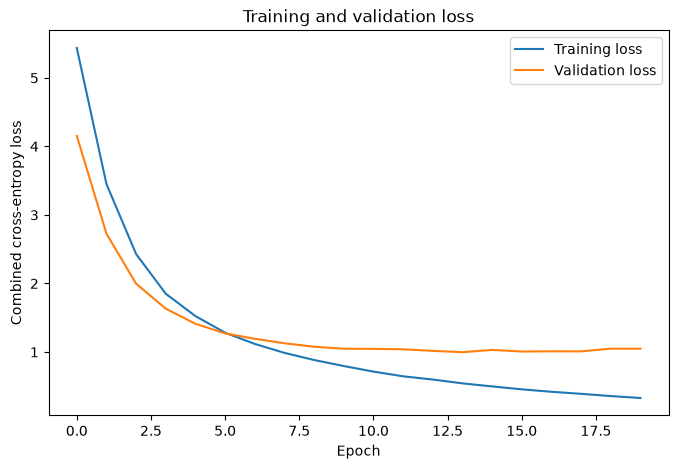

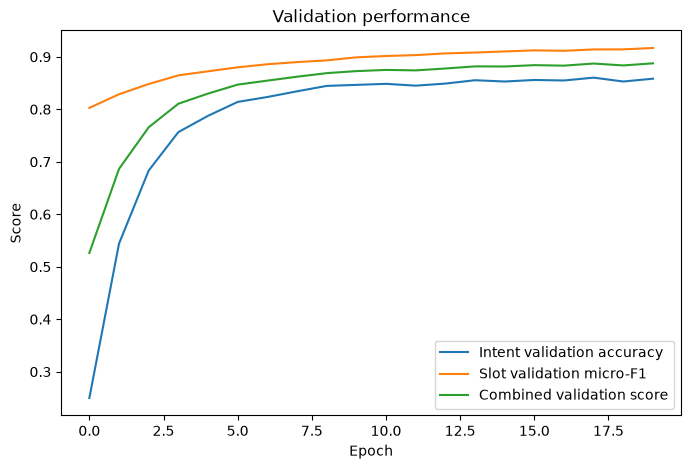

In [11]:
restored_val_metrics = evaluate_intent_and_slots(
    model, dev_loader
)

test_metrics = evaluate_intent_and_slots(model, test_loader)

final_results = pd.DataFrame([
    {
        "Split": "Validation",
        "Intent accuracy": restored_val_metrics["intent_accuracy"],
        "Slot micro-F1": restored_val_metrics["slot_micro_f1"],
    },
    {
        "Split": "Test",
        "Intent accuracy": test_metrics["intent_accuracy"],
        "Slot micro-F1": test_metrics["slot_micro_f1"],
    },
])
display(final_results.round(4))

assert abs(
    restored_val_metrics["intent_accuracy"] - checkpoint["best_val_metrics"]["intent_accuracy"]
) < 1e-6
assert abs(
    restored_val_metrics["slot_micro_f1"] - checkpoint["best_val_metrics"]["slot_micro_f1"]
) < 1e-6

plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Combined cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history["val_accuracy"], label="Intent validation accuracy")
plt.plot(history["val_slot_token_f1"], label="Slot validation micro-F1")
plt.plot(history["val_combined_score"], label="Combined validation score")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation performance")
plt.legend()
plt.show()
